# FoodLens: food image recognition on Food-101

**COMP6826001 Deep Learning · Final Project · Group 4 · BINUS University**

| Name | Student ID |
|---|---|
| Sean Jeremy Henry Sihombing | 2802548530 |
| Josea Immanuel Dihardja | 2802543984 |
| Rheinald Hubert Zhang | 2802445936 |

Progress report, Week 9 (initial experiments): dataset and preprocessing, model construction, experiment plan, and the first training runs.

Run on a GPU: Google Colab (*Runtime → Change runtime type → T4 GPU*) or Kaggle (*Settings → Accelerator → GPU*, *Internet on*; *Save Version → Save & Run All* keeps running with the browser closed). Locally it uses the machine's own GPU.

## 0. Setup

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/seanopegs/foodlens.git"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB or IN_KAGGLE:  # fetch the code from GitHub
    repo = "/content/foodlens" if IN_COLAB else "/kaggle/working/foodlens"
    if os.path.isdir(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)

sys.path.insert(0, os.getcwd())

In [2]:
# On Colab, results and checkpoints go to Google Drive so a disconnect does not lose finished runs.
SAVE_TO_DRIVE = IN_COLAB
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = "/content/drive/MyDrive/foodlens"
else:
    OUTPUT_DIR = "/kaggle/working/outputs" if IN_KAGGLE else "outputs"
RUNS_DIR = os.path.join(OUTPUT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("outputs ->", OUTPUT_DIR)

outputs -> outputs


In [3]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from foodlens.data import (load_food101, subset, build_transforms, make_loaders, pretty_label,
                           IMAGENET_MEAN, IMAGENET_STD, SEED)
from foodlens.models import build_model, count_params, DISPLAY_NAMES
from foodlens.engine import (set_seed, fit, predict, classification_metrics, measure_inference_ms,
                             save_run, load_runs, top_confusions)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 2 if IN_COLAB else min(10, os.cpu_count() or 1)
print("torch", torch.__version__, "| device:", device,
      torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch 2.5.1+cu121 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Dataset

Food-101 (Bossard et al., 2014): 101,000 photos of 101 dishes, 1,000 per class, collected from the food-sharing site foodspotting.com and rescaled to a maximum side of 512 px. We load it from the Hugging Face hub (`ethz/food101`).

The official training split is divided 90/10 into train and validation, stratified per class with seed 42. The official test split (25,250 images, called `validation` on Hugging Face) is only used for the final evaluation. All experiments use this same split.

In [4]:
train_ds, val_ds, test_ds, class_names = load_food101()
NUM_CLASSES = len(class_names)

sizes = pd.DataFrame({"split": ["train", "validation", "test"],
                      "images": [len(train_ds), len(val_ds), len(test_ds)]})
sizes["share"] = (sizes["images"] / sizes["images"].sum() * 100).round(1)
sizes["per class"] = sizes["images"] / NUM_CLASSES
sizes

,split,images,share,per class
0,train,68175,67.5,675.0
1,validation,7575,7.5,75.0
2,test,25250,25.0,250.0


In [5]:
print(NUM_CLASSES, "classes:")
print(", ".join(pretty_label(c) for c in class_names))

101 classes:
Apple pie, Baby back ribs, Baklava, Beef carpaccio, Beef tartare, Beet salad, Beignets, Bibimbap, Bread pudding, Breakfast burrito, Bruschetta, Caesar salad, Cannoli, Caprese salad, Carrot cake, Ceviche, Cheesecake, Cheese plate, Chicken curry, Chicken quesadilla, Chicken wings, Chocolate cake, Chocolate mousse, Churros, Clam chowder, Club sandwich, Crab cakes, Creme brulee, Croque madame, Cup cakes, Deviled eggs, Donuts, Dumplings, Edamame, Eggs benedict, Escargots, Falafel, Filet mignon, Fish and chips, Foie gras, French fries, French onion soup, French toast, Fried calamari, Fried rice, Frozen yogurt, Garlic bread, Gnocchi, Greek salad, Grilled cheese sandwich, Grilled salmon, Guacamole, Gyoza, Hamburger, Hot and sour soup, Hot dog, Huevos rancheros, Hummus, Ice cream, Lasagna, Lobster bisque, Lobster roll sandwich, Macaroni and cheese, Macarons, Miso soup, Mussels, Nachos, Omelette, Onion rings, Oysters, Pad thai, Paella, Pancakes, Panna cotta, Peking duck, Pho, Pizza,

,train,validation,test
min,675.0,75.0,250.0
max,675.0,75.0,250.0
mean,675.0,75.0,250.0


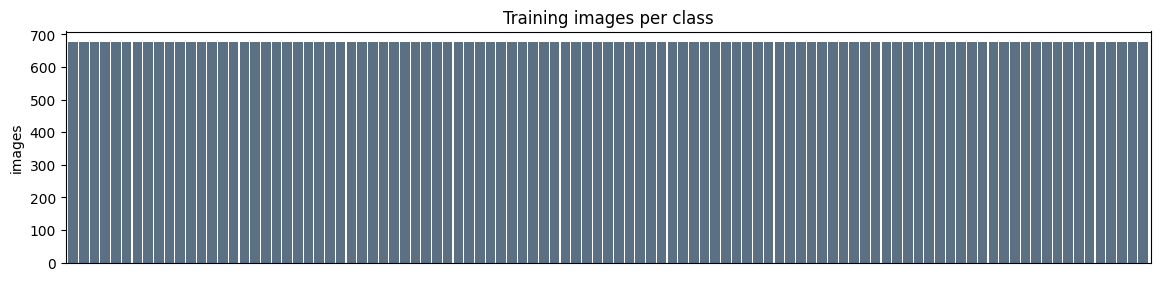

In [6]:
counts = pd.DataFrame({
    name: pd.Series(list(ds["label"])).value_counts().sort_index()
    for name, ds in [("train", train_ds), ("validation", val_ds), ("test", test_ds)]
})
counts.index = [pretty_label(class_names[i]) for i in counts.index]
display(counts.agg(["min", "max", "mean"]))

fig, ax = plt.subplots(figsize=(14, 3))
counts["train"].plot.bar(ax=ax, width=0.9, color="#5b7083")
ax.set_xticks([])
ax.set_ylabel("images")
ax.set_title("Training images per class")
plt.show()

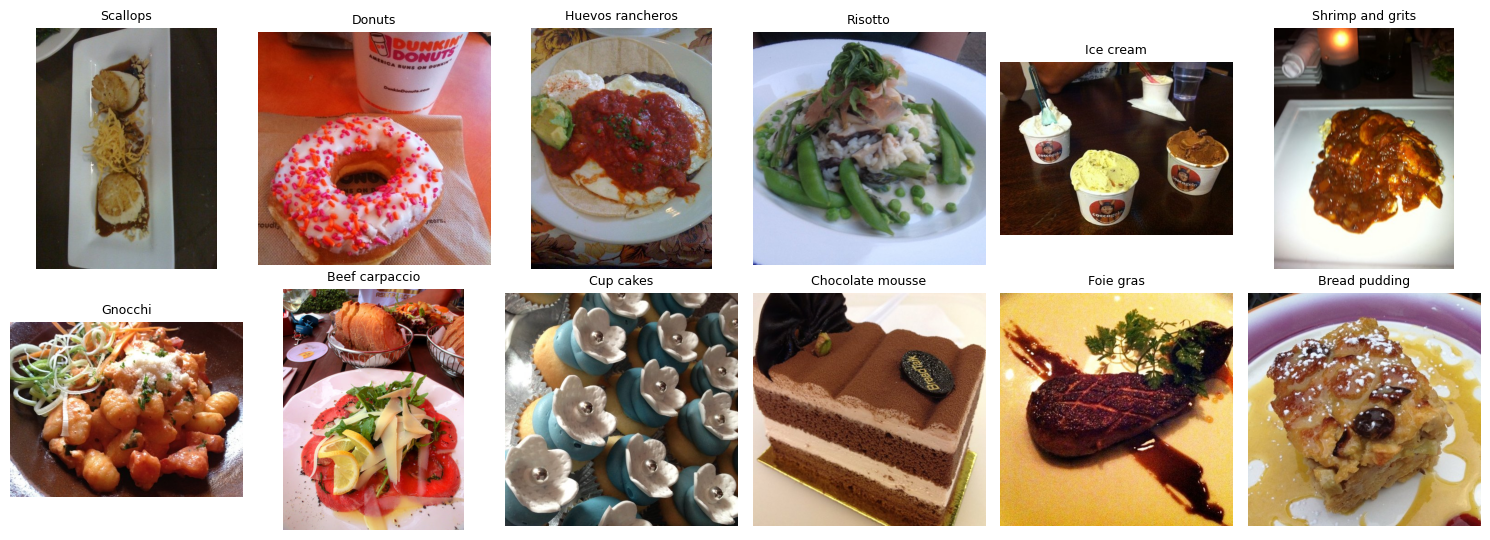

In [7]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(train_ds), 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, i in zip(axes.flat, sample_idx):
    item = train_ds[int(i)]
    ax.imshow(item["image"].convert("RGB"))
    ax.set_title(pretty_label(class_names[item["label"]]), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# image sizes on a random sample of 500 training images
size_sample = train_ds.select(rng.choice(len(train_ds), 500, replace=False).tolist())
dims = pd.DataFrame([im.size for im in size_sample["image"]], columns=["width", "height"])
dims.describe().loc[["min", "50%", "max"]]

,width,height
min,288.0,287.0
50%,512.0,512.0
max,512.0,512.0


**Data quality, bias and limitations**

- The classes are balanced (see the table above), so accuracy is not dominated by a few large classes.
- The dataset authors deliberately did not clean the training images: some have strong colour casts and some are mislabelled. The test images were checked by hand. Part of the training error therefore comes from label noise.
- The photos are user uploads from a food-sharing site: mostly restaurant dishes, mostly Western cuisine plus some East and Southeast Asian dishes (ramen, pho, fried rice, ...). Most Indonesian dishes are not included, and the model can only answer with one of these 101 classes.
- Size, lighting, angle and background vary a lot, and some photos show more than one dish.

## 2. Preprocessing

| Step | Train | Val / test | Why |
|---|---|---|---|
| Convert to RGB | yes | yes | every input needs 3 channels |
| Resize shorter side to 256 px | yes | yes | photos have different sizes; keeps the aspect ratio so food is not stretched |
| Random 224 × 224 crop | yes | | the dish is not always centred; adds position variety |
| Centre 224 × 224 crop | | yes | deterministic, so every model is scored on identical inputs |
| Horizontal flip (p = 0.5) | yes | | a mirrored dish is still the same dish |
| Rotation ±15° | yes | | photos are taken at slightly different angles |
| Colour jitter (brightness, contrast, saturation ±20%) | yes | | restaurant lighting varies a lot |
| Normalise with ImageNet mean / std | yes | yes | required by the pretrained models; used for the custom CNN too so all models get identical inputs |
| Label to integer 0–100 | yes | yes | from the dataset's `ClassLabel` feature |

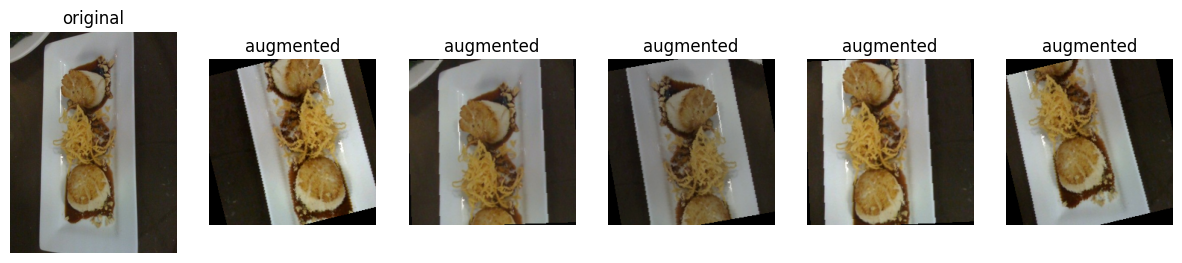

In [9]:
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
to_image = lambda t: (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

train_tf = build_transforms(train=True)
original = train_ds[int(sample_idx[0])]["image"].convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(original)
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(to_image(train_tf(original)))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

## 3. Models

All models take a 224 × 224 RGB image and output 101 logits; softmax turns them into class probabilities. Loss: cross-entropy (multi-class, one label per image). Optimizer: Adam.

| Model | Pretrained on | Trained layers |
|---|---|---|
| Custom CNN (baseline) | nothing, random initialisation | all |
| MobileNetV2 | ImageNet-1K (1.28 M images, 1,000 classes) | last 3 feature blocks + new 101-class layer |
| EfficientNet-B0 | ImageNet-1K | last 3 feature blocks + new 101-class layer |

**Custom CNN.** Five blocks of (Conv 3×3 → BatchNorm → ReLU) × 2 → MaxPool reduce the image from 224 px to 7 px while the channels grow 32 → 64 → 128 → 256 → 256. Global average pooling, dropout (0.3) and one fully connected layer give the 101 outputs.

**MobileNetV2** uses inverted residual blocks with depthwise separable convolutions, so it is small and fast on a CPU, which suits a web app. **EfficientNet-B0** scales depth, width and resolution together and usually reaches higher accuracy for its size.

**Fine-tuning strategy.** The early blocks of a pretrained network detect generic edges, colours and textures, which transfer well from ImageNet, so they stay frozen together with their BatchNorm statistics. The last three feature blocks and a new 101-class output layer are trained, which adapts the high-level features to food while keeping training fast and reducing overfitting.

In [10]:
print(build_model("custom_cnn", NUM_CLASSES))

CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inpl

In [11]:
rows = []
for arch in ["custom_cnn", "mobilenet_v2", "efficientnet_b0"]:
    total, trainable = count_params(build_model(arch, NUM_CLASSES))
    rows.append({"model": DISPLAY_NAMES[arch], "total params (M)": total / 1e6,
                 "trainable params (M)": trainable / 1e6})
pd.DataFrame(rows).round(2)

,model,total params (M),trainable params (M)
0,Custom CNN,2.38,2.38
1,MobileNetV2,2.35,1.34
2,EfficientNet-B0,4.14,3.29


## 4. Experiment plan

Each scenario changes exactly one variable relative to the baseline. Everything else stays fixed: data split, preprocessing, loss, optimizer, up to 15 epochs with early stopping on validation loss (patience 3), seed 42.

In [12]:
BASE = dict(arch="custom_cnn", lr=1e-3, batch_size=32, augment=True, max_epochs=15, patience=3)

EXPERIMENTS = {
    "Baseline": dict(BASE),
    "E1": {**BASE, "lr": 1e-4},
    "E2": {**BASE, "batch_size": 16},
    "E3": {**BASE, "arch": "mobilenet_v2"},
    "E4": {**BASE, "arch": "efficientnet_b0"},
}

PLAN = pd.DataFrame([
    ("Baseline", "", "Custom CNN, lr 1e-3, batch 32", "reference point, trained from scratch"),
    ("E1", "learning rate", "1e-3 → 1e-4", "does a smaller step size converge more smoothly and generalise better?"),
    ("E2", "batch size", "32 → 16", "noisier gradients and more updates per epoch: effect on accuracy and time"),
    ("E3", "architecture", "Custom CNN → MobileNetV2 (ImageNet)", "lightweight pretrained model suited to a web app"),
    ("E4", "architecture", "Custom CNN → EfficientNet-B0 (ImageNet)", "higher accuracy per parameter than a plain CNN?"),
], columns=["experiment", "variable changed", "value", "why"]).set_index("experiment")
PLAN

,variable changed,value,why
experiment,,,
Baseline,,"Custom CNN, lr 1e-3, batch 32","reference point, trained from scratch"
E1,learning rate,1e-3 → 1e-4,does a smaller step size converge more smoothl...
E2,batch size,32 → 16,noisier gradients and more updates per epoch: ...
E3,architecture,Custom CNN → MobileNetV2 (ImageNet),lightweight pretrained model suited to a web app
E4,architecture,Custom CNN → EfficientNet-B0 (ImageNet),higher accuracy per parameter than a plain CNN?


## 5. Training

Set `RUN_NOW` to the scenarios for this session. Finished runs are saved in `OUTPUT_DIR` and skipped next time, and the training state is saved after every epoch, so a run cut off by a Colab disconnect continues from its last finished epoch when the notebook is run again.

The five runs reported here were trained on Kaggle (Tesla T4 GPU, one *Save & Run All* version, 4.4 hours in total); their saved results were copied into `outputs/`, so the cell below skips them and the sections after it read those results.

`QUICK_CHECK = True` trains on a small subset to test the pipeline only. Those runs are stored with a `_quick` suffix and their numbers must not be reported.

In [13]:
RUN_NOW = ["Baseline", "E1", "E3", "E4", "E2"]
QUICK_CHECK = False


def run_experiment(name, cfg):
    run_name = f"{name}_quick" if QUICK_CHECK else name
    run_dir = os.path.join(RUNS_DIR, run_name)
    if os.path.exists(os.path.join(run_dir, "metrics.json")):
        print(f"{run_name}: already finished, skipping")
        return
    set_seed(SEED)
    if QUICK_CHECK:
        tr, va, te = subset(train_ds, 2020), subset(val_ds, 505), subset(test_ds, 505)
    else:
        tr, va, te = train_ds, val_ds, test_ds
    train_loader, val_loader, test_loader = make_loaders(
        tr, va, te, batch_size=cfg["batch_size"], augment=cfg["augment"], num_workers=NUM_WORKERS)

    model = build_model(cfg["arch"], NUM_CLASSES).to(device)
    total, trainable = count_params(model)
    print(f"=== {run_name} | {cfg} | params {total:,} (trainable {trainable:,})")

    result = fit(model, train_loader, val_loader, device, lr=cfg["lr"],
                 max_epochs=cfg["max_epochs"], patience=cfg["patience"],
                 ckpt_path=os.path.join(OUTPUT_DIR, "checkpoints", f"{run_name}.pt"),
                 state_path=os.path.join(OUTPUT_DIR, "state", f"{run_name}.pt"),
                 ckpt_meta={"arch": cfg["arch"], "class_names": class_names,
                            "experiment": name, "config": cfg})

    y_true, probs = predict(model, test_loader, device)
    metrics = classification_metrics(y_true, probs)
    metrics.update(
        params_total=total, params_trainable=trainable,
        best_epoch=result["best_epoch"], epochs_run=result["epochs_run"],
        train_time_min=result["train_time_s"] / 60,
        inference_ms_cpu=measure_inference_ms(copy.deepcopy(model).cpu(), torch.device("cpu")),
        quick_check=QUICK_CHECK,
    )
    if device.type == "cuda":
        metrics["inference_ms_gpu"] = measure_inference_ms(model, device)
    save_run(run_dir, cfg, result["history"], metrics, y_true, probs)
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in metrics.items()})


for name in RUN_NOW:
    run_experiment(name, EXPERIMENTS[name])

Baseline: already finished, skipping
E1: already finished, skipping
E3: already finished, skipping
E4: already finished, skipping
E2: already finished, skipping


## 6. Results

In [14]:
runs, histories = load_runs(RUNS_DIR)
if runs.empty:
    print("No finished runs yet.")
else:
    table = runs.copy()
    table.index.name = "run"
    base_names = [r.removesuffix("_quick") for r in table.index]
    table["variable changed"] = PLAN["variable changed"].reindex(base_names).fillna("").values
    table["value"] = PLAN["value"].reindex(base_names).fillna("").values
    columns = ["variable changed", "value", "test_acc", "test_top5_acc", "macro_precision",
               "macro_recall", "macro_f1", "best_epoch", "epochs_run", "train_time_min",
               "params_total", "params_trainable", "inference_ms_cpu"]
    display(table[columns].style.format({
        "test_acc": "{:.2%}", "test_top5_acc": "{:.2%}", "macro_precision": "{:.3f}",
        "macro_recall": "{:.3f}", "macro_f1": "{:.3f}", "train_time_min": "{:.1f}",
        "params_total": "{:,}", "params_trainable": "{:,}", "inference_ms_cpu": "{:.1f}",
    }))

,variable changed,value,test_acc,test_top5_acc,macro_precision,macro_recall,macro_f1,best_epoch,epochs_run,train_time_min,params_total,params_trainable,inference_ms_cpu
run,,,,,,,,,,,,,
Baseline,,"Custom CNN, lr 1e-3, batch 32",68.15%,89.80%,0.694,0.682,0.680,15,15,58.2,"2,379,845","2,379,845",40.4
E1,learning rate,1e-3 → 1e-4,62.88%,87.02%,0.649,0.629,0.624,14,15,58.6,"2,379,845","2,379,845",46.9
E2,batch size,32 → 16,67.83%,89.28%,0.691,0.678,0.676,15,15,61.7,"2,379,845","2,379,845",40.7
E3,architecture,Custom CNN → MobileNetV2 (ImageNet),78.03%,94.60%,0.784,0.780,0.778,8,11,40.4,"2,353,253","1,335,461",22.1
E4,architecture,Custom CNN → EfficientNet-B0 (ImageNet),81.65%,95.84%,0.823,0.816,0.817,6,9,34.9,"4,136,929","3,285,121",29.3


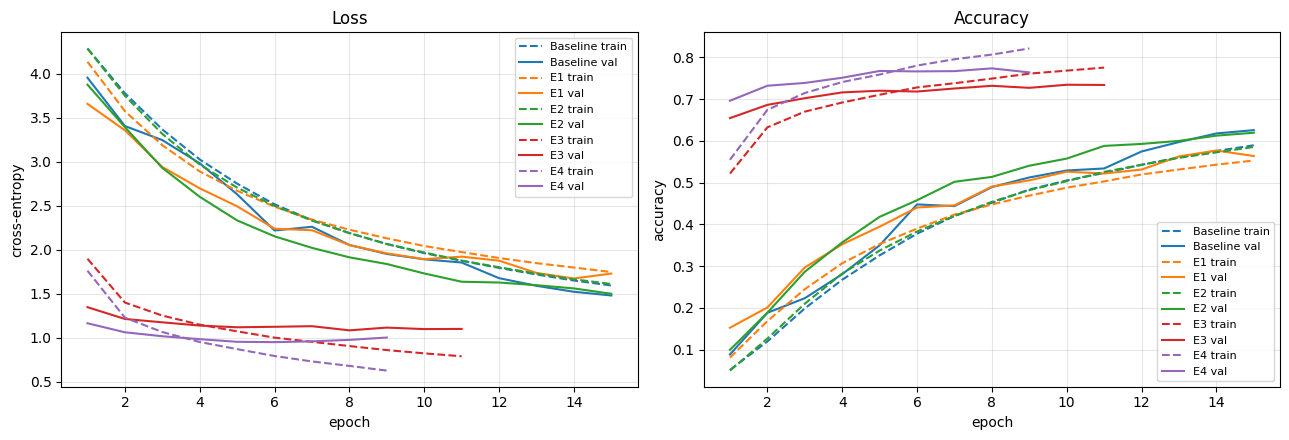

In [15]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in histories.items():
    line, = ax_loss.plot(hist.epoch, hist.train_loss, "--", label=f"{name} train")
    ax_loss.plot(hist.epoch, hist.val_loss, "-", color=line.get_color(), label=f"{name} val")
    ax_acc.plot(hist.epoch, hist.train_acc, "--", color=line.get_color(), label=f"{name} train")
    ax_acc.plot(hist.epoch, hist.val_acc, "-", color=line.get_color(), label=f"{name} val")
ax_loss.set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
ax_acc.set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
def training_summary(hist, max_epochs=BASE["max_epochs"]):
    best = hist.loc[hist.val_loss.idxmin()]
    return pd.Series({
        "best epoch": int(best.epoch),
        "train acc at best": best.train_acc,
        "val acc at best": best.val_acc,
        "train - val acc (pts)": (best.train_acc - best.val_acc) * 100,
        "val loss at end - best": hist.val_loss.iloc[-1] - best.val_loss,
        "stopped early": len(hist) < max_epochs,
    })

pd.DataFrame({name: training_summary(h) for name, h in histories.items()}).T

,best epoch,train acc at best,val acc at best,train - val acc (pts),val loss at end - best,stopped early
Baseline,15,0.589292,0.625611,-3.63183,0.0,False
E1,14,0.542941,0.576898,-3.395673,0.056129,False
E2,15,0.585288,0.619406,-3.411808,0.0,False
E3,8,0.748999,0.731749,1.724972,0.016031,True
E4,6,0.780183,0.766205,1.397873,0.052375,True


**Reading the curves**

- *Overfitting*: validation loss turns upward while training loss keeps falling, with a growing train–validation accuracy gap.
- *Underfitting*: both losses stay high and accuracy is still rising when training ends.
- *Stable*: both losses fall together and level off.

Training accuracy is measured on augmented images with dropout active, so early in training it can sit below validation accuracy.

## 7. Error analysis (first look)

In [17]:
RUN_TO_INSPECT = runs["test_acc"].idxmax() if not runs.empty else None  # best run

if RUN_TO_INSPECT:
    pred = np.load(os.path.join(RUNS_DIR, RUN_TO_INSPECT, "predictions.npz"))
    print("run:", RUN_TO_INSPECT)
    display(top_confusions(pred["y_true"], pred["y_pred"], class_names, k=10))

run: E4


,true,predicted,count,share of true class
0,steak,filet_mignon,76,0.304
1,pork_chop,filet_mignon,33,0.132
2,prime_rib,steak,27,0.108
3,chocolate_cake,chocolate_mousse,27,0.108
4,ravioli,gnocchi,26,0.104
5,gyoza,dumplings,25,0.100
6,tuna_tartare,beef_tartare,24,0.096
7,falafel,crab_cakes,24,0.096
8,shrimp_and_grits,gnocchi,24,0.096
9,chocolate_mousse,tiramisu,23,0.092


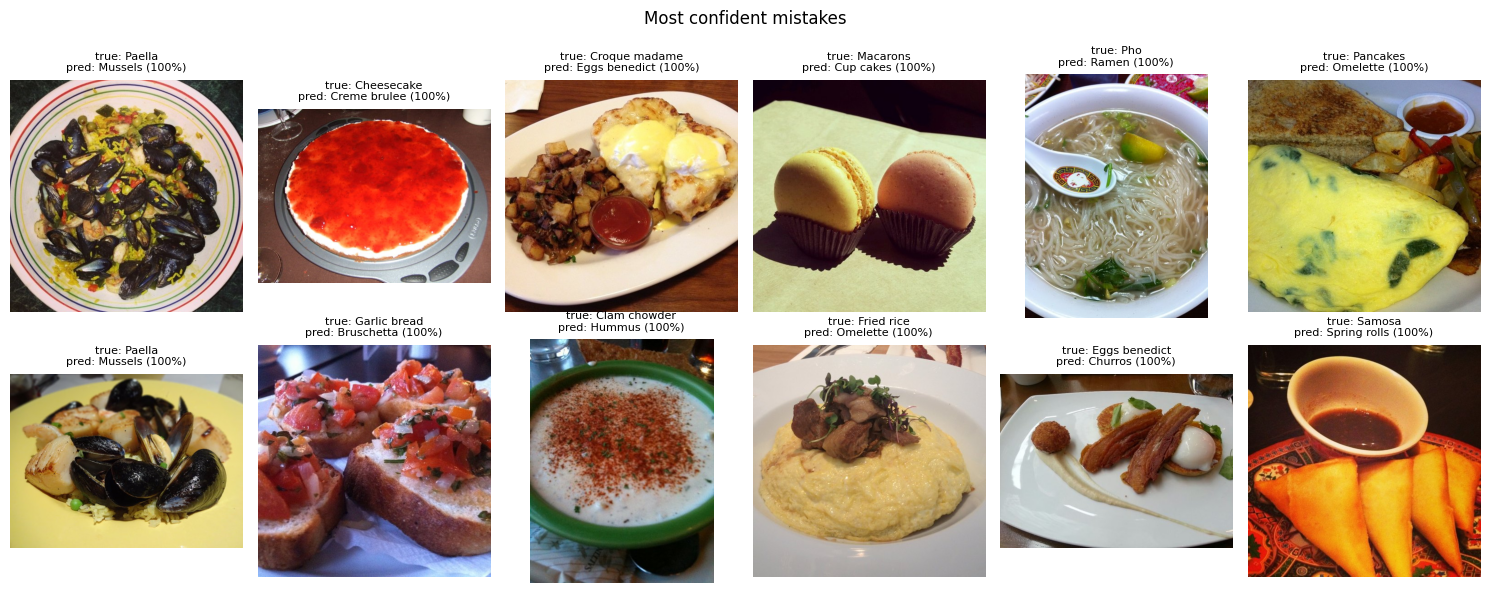

In [18]:
if RUN_TO_INSPECT:
    eval_set = subset(test_ds, 505) if RUN_TO_INSPECT.endswith("_quick") else test_ds
    wrong = np.where(pred["y_pred"] != pred["y_true"])[0]
    confident_wrong = wrong[np.argsort(-pred["confidence"][wrong])][:12]
    fig, axes = plt.subplots(2, 6, figsize=(15, 6))
    for ax, i in zip(axes.flat, confident_wrong):
        ax.imshow(eval_set[int(i)]["image"].convert("RGB"))
        ax.set_title(f"true: {pretty_label(class_names[pred['y_true'][i]])}\n"
                     f"pred: {pretty_label(class_names[pred['y_pred'][i]])} "
                     f"({pred['confidence'][i]:.0%})", fontsize=8)
        ax.axis("off")
    plt.suptitle("Most confident mistakes")
    plt.tight_layout()
    plt.show()

## 8. Next steps

- Train E2, E3 and E4 on the same split and complete the comparison table (accuracy, macro-F1, training time, parameters, CPU inference time).
- Full error analysis: which dishes get confused and why (similar appearance, label noise, photo quality).
- Choose the model to deploy by weighing accuracy against CPU inference time and model size.
- Put the chosen checkpoint in the Streamlit app (`app.py`) and run the user test with 10–15 students.